<a href="https://colab.research.google.com/github/Rogerio-mack/IMT_CD_2026/blob/main/IMT_CD_P3_2026_solucao.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns


In [ ]:
#@markdown Nome **COMPLETO** e RA

Nome = 'Anna Karenina' #@param {type:"string"}
RA = '22.01164-0' #@param {type:"string"}
#@markdown

suffix_file = RA.replace('.','')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
from IPython.display import display

path = 'https://github.com/Rogerio-mack/work/raw/main/pdata/'

#@markdown Salve o seu notebook com **IMT_CD_P3_2026_\<seu_nome\>.ipynb**

#@markdown Execute esta célula para prosseguir.

# Data



# **CASE: Telemarketing**

Este Case envolve dados da campanha de marketing de depósitos a prazo de uma instituição bancária. É um problema de classificação e o objetivo é prever, dentre todos os clientes, quais têm mais propensão a subscrever um serviço de depósitos a prazo e, portanto, quais clientes deverão ser contatados pelo Call-Center (contato telefônico) com mais chances de sucesso da campanha.

## Dados

-	**Atributos do cliente**
  -	age: idade do cliente  
  -	age: tipo de trabalho
  -	marital: estado civil  
  -	education: nível de escolaridade mais alto do cliente. Esta é uma categoria ordinal.
  -	default: possui crédito em caso de inadimplência?
  -	balance: saldo médio anual
  -	housing: Possui empréstimo habitacional?
  -	loan: Possui empréstimo pessoal?  

-	**Relacionado com o último contato de campanhas**
  -	contact: tipo de comunicação de contato. `unknown` é uma categoria de contato para efeito da classificação.
  -	duration: duração do último contato, em segundos. Durações de 0 até pouco segundos são também contabilizadas como tentativas de contato (ligação não atendida etc.)
  -	year, day, month: ano, mês e dia do último dia de contato

-	**Outros atributo**
  -	campaign: código da campanha
  -	pdays: número de dias decorridos desde o último contato com o cliente em uma campanha anterior (-1 significa que o cliente não foi contatado anteriormente).
  -	previous: número de contatos realizados antes desta campanha e para este cliente
  -	poutcome: resultado da campanha de marketing anterior. `unknown` é uma categoria de contato para efeito da classificação.

-	**Variável alvo**
  -	subscribe: O cliente subscreveu um depósito a prazo?

-	**Outras informações sobre os dados**
  -	`unknown`, é empregado para valores ausentes, exceto nos casos em que é explicitamente considerado como categoria válida.

## Pré-Processamento

As seguintes decisões foram tomadas previamente pelo Cientista de Dados para o pré-processamento dos dados, em acordo com a área de negócio, para a tarefa de classificação:

1. **Dados discrepantes**. Os dados possuem muitos outliers e, por isso, são imprescindíveis para análise e não devem ser descartados. Entretanto, dados excessivamente discrepantes e de pouquíssimas ocorrências devem estar associados a erro nos dados. Havendo poucas ocorrências esses registros devem ser excluídos da análise.

2. **Dados ausentes**. Dados ausentes devem ser valores imputados de acordo com a distribuição de `education` ou `job`, o que for mais adequado para compatibilizar os dados. Na ausência do valor de referência o valor mais frequente deve ser empregado.

3. **Dados categóricos**. Dados categóricos ordinais, para preservar a ordem, serão codificados por rótulo. Os demais, por `one hot-encode`.



In [ ]:
path = 'https://github.com/Rogerio-mack/work/raw/main/pdata/'

df = pd.read_csv(path + 'bank-marketing-processed.csv')
df_cases = pd.read_csv(path + 'bank-marketing-cases.csv')

display(df.head())
display(df_cases.head())
df.shape, df_cases.shape

,subscribe,age,job,marital,education,default,balance,housing,loan,contact,duration,campaign,pdays,previous,poutcome,year,day,month
0,no,52,admin.,married,primary,no,321,yes,no,unknown,141,4,-1,0,unknown,2026,30,may
1,no,35,blue-collar,single,unknown,no,217,yes,no,cellular,107,11,-1,0,unknown,2026,30,jul
2,no,29,management,married,tertiary,no,6586,no,no,cellular,176,1,-1,0,unknown,2026,10,jul
3,no,30,student,single,secondary,no,5836,no,no,cellular,165,2,-1,0,unknown,2026,27,apr
4,no,49,self-employed,single,secondary,no,766,yes,no,cellular,150,4,-1,0,unknown,2026,7,jul


,age,job,marital,education,default,balance,housing,loan,contact,duration,campaign,pdays,previous,poutcome,year,day,month
0,34,blue-collar,married,secondary,no,243,yes,no,unknown,291,1,-1,0,unknown,2026,5,may
1,29,admin.,single,secondary,no,43,yes,no,unknown,179,2,-1,0,unknown,2026,9,may
2,59,blue-collar,married,primary,no,99,yes,no,cellular,43,1,261,3,failure,2026,5,feb
3,52,admin.,single,secondary,no,1964,no,yes,unknown,332,1,-1,0,unknown,2026,28,may
4,31,admin.,single,tertiary,no,701,yes,no,unknown,301,2,-1,0,unknown,2026,23,may


((45165, 18), (46, 17))

In [ ]:
df_original = df.copy()

# Clean Data

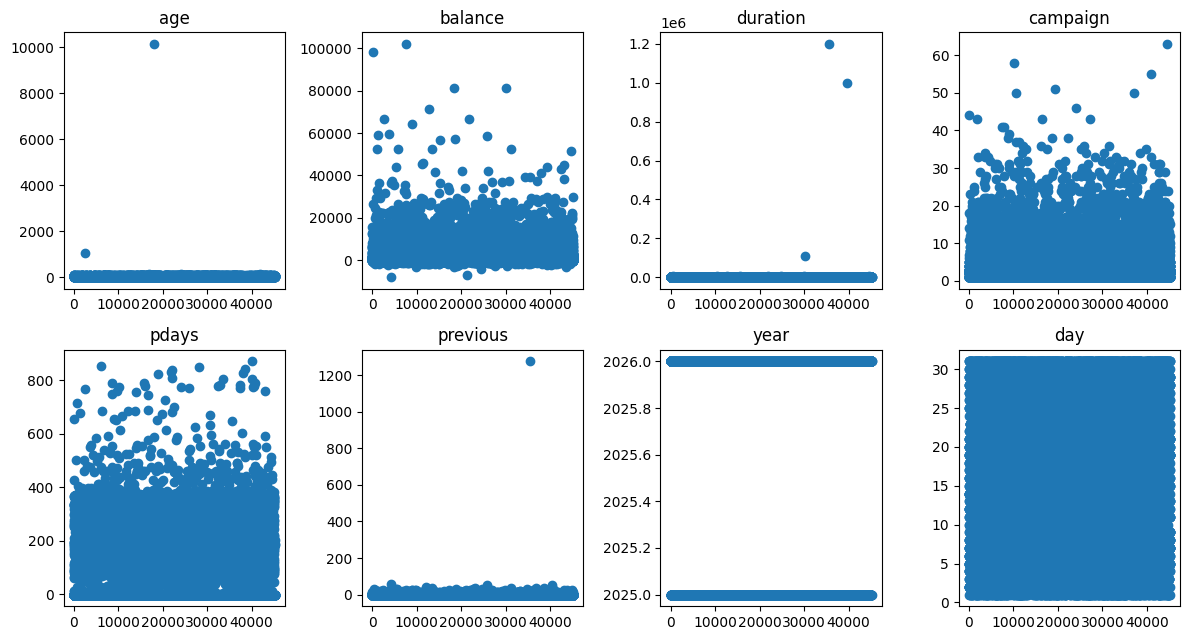

In [ ]:
plt.figure(figsize=(12, 6.5))

for i, c in enumerate(df.select_dtypes('number').columns):
  plt.subplot(2,4,i+1)
  plt.scatter(df.index,df[c])
  # plt.scatter(df.index,np.log1p(df[c]))
  # sns.stripplot(df[c])
  plt.title(c)

plt.tight_layout()
plt.show()


In [ ]:
display(df.describe().T)
print()
for c in ['age', 'balance', 'duration', 'campaign', 'pdays', 'previous']:
    valores = sorted(df[c].unique().tolist())
    print(f'{c}: menores {valores[:5]} | maiores {valores[-5:]}')

,count,mean,std,min,25%,50%,75%,max
age,45165.0,41.183527,48.987540,1.0,33.0,39.0,48.0,10152.0
balance,45165.0,1362.053891,3045.092241,-8019.0,72.0,448.0,1427.0,102127.0
duration,45165.0,309.352530,7370.825585,0.0,103.0,180.0,319.0,1199891.0
campaign,45165.0,2.764021,3.098603,1.0,1.0,2.0,3.0,63.0
pdays,45165.0,40.216185,100.159641,-1.0,-1.0,-1.0,-1.0,871.0
previous,45165.0,0.602436,6.292841,0.0,0.0,0.0,0.0,1275.0
year,45165.0,2025.878269,0.326979,2025.0,2026.0,2026.0,2026.0,2026.0
day,45165.0,15.807196,8.322781,1.0,8.0,16.0,21.0,31.0



age: menores [1, 5, 18, 19, 20] | maiores [94, 95, 152, 1052, 10152]
balance: menores [-8019, -6847, -4057, -3372, -3313] | maiores [66721, 71188, 81204, 98417, 102127]
duration: menores [0, 1, 2, 3, 4] | maiores [3881, 4918, 110891, 999999, 1199891]
campaign: menores [1, 2, 3, 4, 5] | maiores [50, 51, 55, 58, 63]
pdays: menores [-1, 1, 2, 3, 4] | maiores [838, 842, 850, 854, 871]
previous: menores [0, 1, 2, 3, 4] | maiores [41, 51, 55, 58, 1275]


In [ ]:
df = df[ (df.age < 100) & (df.age >= 18) ]

In [ ]:
df = df[ df.duration < 5000 ]

In [ ]:
df = df[ df.previous < 60 ]

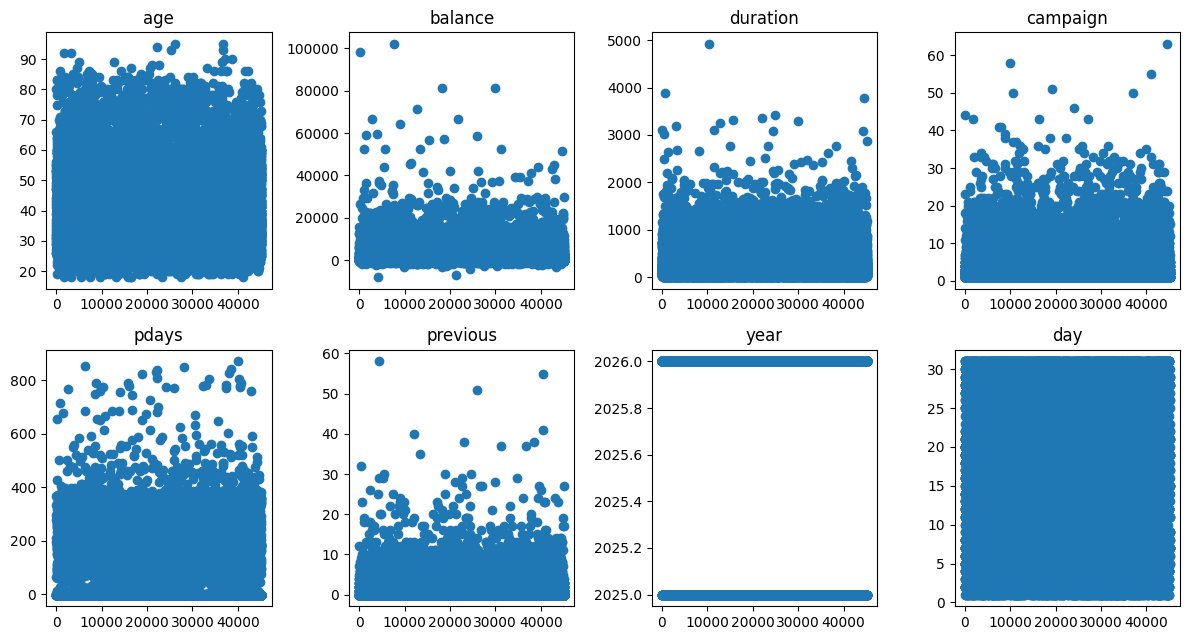

In [ ]:
plt.figure(figsize=(12, 6.5))

for i, c in enumerate(df.select_dtypes('number').columns):
  plt.subplot(2,4,i+1)
  plt.scatter(df.index,df[c])
  # plt.scatter(df.index,np.log1p(df[c]))
  # sns.stripplot(df[c])
  plt.title(c)

plt.tight_layout()
plt.show()

In [ ]:
df_original.shape, df.shape, df_original.shape[0] - df.shape[0]

((45165, 18), (45154, 18), 11)

In [ ]:
df.campaign.nunique()

48

# Pre-Processing

In [ ]:
def pre_process(df):

  month_map = {
      'jan': 1, 'feb': 2, 'mar': 3, 'apr': 4, 'may': 5, 'jun': 6,
      'jul': 7, 'aug': 8, 'sep': 9, 'oct': 10, 'nov': 11, 'dec': 12
  }
  df['month_nr'] = df['month'].map(month_map)

  df['contact_date'] = pd.to_datetime(df['year'].astype(str) + '-' + df['month_nr'].astype(str) + '-' + df['day'].astype(str))

  today = pd.to_datetime('2026-09-24')

  df['last_contact'] = (today - df['contact_date']).dt.days

  df.drop(columns=['month_nr','month','year','contact_date'], inplace=True)
  return df

df = pre_process(df)
df_cases = pre_process(df_cases)


In [ ]:
from pandas.api.types import CategoricalDtype

cat_type = CategoricalDtype(categories=["unknown", "primary", "secondary","tertiary"], ordered=True)
df.education = df.education.astype(cat_type)

for c in df.select_dtypes('object').columns:
  df[c] = df[c].astype('category')

df.campaign = df.campaign.astype('category')

ordinal_cols = []
non_ordinal_cols = []

for col in df.columns:
    if isinstance(df[col].dtype, pd.CategoricalDtype):
        if df[col].cat.ordered:
            ordinal_cols.append(col)
        else:
            non_ordinal_cols.append(col)

numeric_cols = df.select_dtypes('number').columns

print("Ordinal Categorical Columns:", ordinal_cols)
print("Non-Ordinal Categorical Columns:", non_ordinal_cols)
print("Numeric Columns:", list(numeric_cols))


Ordinal Categorical Columns: ['education']
Non-Ordinal Categorical Columns: ['subscribe', 'job', 'marital', 'default', 'housing', 'loan', 'contact', 'campaign', 'poutcome']
Numeric Columns: ['age', 'balance', 'duration', 'pdays', 'previous', 'day', 'last_contact']


# Train, Test split

In [ ]:
from sklearn.model_selection import train_test_split

seed = 42
X_train, X_test, y_train, y_test = train_test_split(df.drop(columns=['subscribe']), df.subscribe, test_size=0.2, random_state=seed, stratify=df.subscribe)



In [ ]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((36123, 16), (9031, 16), (36123,), (9031,))

# Impute nulls

## X_train

In [ ]:
print("Contagem de valores 'unknown' por coluna no DataFrame df:")
for col in df.columns:
    if 'unknown' in df[col].values:
        unknown_count = (df[col] == 'unknown').sum()
        print(f"Coluna '{col}': {unknown_count} valores 'unknown'")


Contagem de valores 'unknown' por coluna no DataFrame df:
Coluna 'job': 286 valores 'unknown'
Coluna 'education': 1854 valores 'unknown'
Coluna 'contact': 12998 valores 'unknown'
Coluna 'poutcome': 36911 valores 'unknown'


In [ ]:
def impute_values(fill_df, fill_field, by_df, fill_by, null_value, seed=42):
  seed = 42
  np.random.seed(seed)

  print(f"Value counts for {fill_field} before imputation:")
  print(fill_df[fill_field].value_counts())
  print(f"\nPercentage of '{null_value}' values in '{fill_field}' field before imputation:")
  print((fill_df[fill_field] == null_value).sum() / len(fill_df) * 100)
  print()

  # Using fill_df to get the indices of null values
  null_values_indices = fill_df[fill_df[fill_field] == null_value].index

  for i in null_values_indices:
    # Ensure filtering is done on by_df, which should be X_train in this context
    values_by = by_df[(by_df[fill_by] == fill_df.loc[i, fill_by]) & (by_df[fill_field] != null_value)][fill_field]
    if len(values_by) > 0:
      fill_df.loc[i, fill_field] = np.random.choice(values_by)
    else:
      # Fallback to general mode if no specific group has valid values
      fill_df.loc[i, fill_field] = by_df[by_df[fill_field] != null_value][fill_field].mode()[0]
      print(f'Warning: no valid {fill_field} values by {fill_by} for this record (index {i}):')
      # print(fill_df.loc[i, :])

  print(f"Value counts for {fill_field} after imputation:")
  print(fill_df[fill_field].value_counts())
  print(f"\nPercentage of '{null_value}' values in '{fill_field}' field after imputation:")
  print((fill_df[fill_field] == null_value).sum() / len(fill_df) * 100)
  print()

  print(f"Value imputation counts for {fill_field}:")
  # Only show counts for the actually imputed indices
  print(fill_df.loc[null_values_indices,fill_field].value_counts())
  print(f"Sum of imputed values: {len(null_values_indices)}")


# Impute 'job' in X_train
fill_df = X_train
fill_field = 'job'
by_df = X_train
fill_by = 'education'
null_value = 'unknown'
impute_values(fill_df, fill_field, by_df, fill_by, null_value, seed=42)

print("\n" + "="*50 + "\n") # Separator for clarity

# Impute 'education' in X_train
fill_df = X_train
fill_field = 'education'
by_df = X_train
fill_by = 'job'
null_value = 'unknown'
impute_values(fill_df, fill_field, by_df, fill_by, null_value, seed=42)

print("\n" + "="*50 + "\n")



Value counts for job before imputation:
job
blue-collar      7764
management       7542
technician       6080
admin.           4111
services         3304
retired          1826
self-employed    1256
entrepreneur     1212
unemployed       1040
housemaid        1008
student           750
unknown           230
Name: count, dtype: int64

Percentage of 'unknown' values in 'job' field before imputation:
0.6367134512637378

Value counts for job after imputation:
job
blue-collar      7817
management       7579
technician       6118
admin.           4136
services         3322
retired          1845
self-employed    1264
entrepreneur     1220
unemployed       1049
housemaid        1015
student           758
unknown             0
Name: count, dtype: int64

Percentage of 'unknown' values in 'job' field after imputation:
0.0

Value imputation counts for job:
job
blue-collar      53
technician       38
management       37
admin.           25
retired          19
services         18
unemployed        9


## X_test

In [ ]:
# Impute 'job' in X_test
fill_df = X_test
fill_field = 'job'
by_df = X_train
fill_by = 'education'
null_value = 'unknown'
impute_values(fill_df, fill_field, by_df, fill_by, null_value, seed=42)

print("\n" + "="*50 + "\n")

# Impute 'education' in X_test
fill_df = X_test
fill_field = 'education'
by_df = X_train
fill_by = 'job'
null_value = 'unknown'
impute_values(fill_df, fill_field, by_df, fill_by, null_value, seed=42)

print("\n" + "="*50 + "\n")



Value counts for job before imputation:
job
blue-collar      1955
management       1903
technician       1509
admin.           1055
services          842
retired           436
self-employed     322
entrepreneur      275
unemployed        262
housemaid         230
student           186
unknown            56
Name: count, dtype: int64

Percentage of 'unknown' values in 'job' field before imputation:
0.6200863691728491

Value counts for job after imputation:
job
blue-collar      1988
management       1908
technician       1512
admin.           1058
services          846
retired           436
self-employed     324
entrepreneur      277
unemployed        263
housemaid         231
student           188
unknown             0
Name: count, dtype: int64

Percentage of 'unknown' values in 'job' field after imputation:
0.0

Value imputation counts for job:
job
blue-collar      33
management        5
services          4
admin.            3
technician        3
entrepreneur      2
student           2


## df_cases

In [ ]:
# Impute 'job' in df_case
fill_df = df_cases
fill_field = 'job'
by_df = X_train
fill_by = 'education'
null_value = 'unknown'
impute_values(fill_df, fill_field, by_df, fill_by, null_value, seed=42)

print("\n" + "="*50 + "\n")

# Impute 'education' in X_test
fill_df = df_cases
fill_field = 'education'
by_df = X_train
fill_by = 'job'
null_value = 'unknown'
impute_values(fill_df, fill_field, by_df, fill_by, null_value, seed=42)

print("\n" + "="*50 + "\n")



Value counts for job before imputation:
job
blue-collar      11
management        9
technician        8
services          6
admin.            4
retired           2
unknown           2
unemployed        1
student           1
self-employed     1
housemaid         1
Name: count, dtype: int64

Percentage of 'unknown' values in 'job' field before imputation:
4.3478260869565215

Value counts for job after imputation:
job
blue-collar      12
management       10
technician        8
services          6
admin.            4
retired           2
student           1
unemployed        1
self-employed     1
housemaid         1
Name: count, dtype: int64

Percentage of 'unknown' values in 'job' field after imputation:
0.0

Value imputation counts for job:
job
blue-collar    1
management     1
Name: count, dtype: int64
Sum of imputed values: 2


Value counts for education before imputation:
education
secondary    29
tertiary      8
primary       6
unknown       3
Name: count, dtype: int64

Percentage of 

# Encode

## OHE

In [ ]:
from sklearn.preprocessing import OneHotEncoder

# Initialize OneHotEncoder
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

# Remove 'accept' from non_ordinal_cols if it exists, as it's the target variable
features_to_encode = [col for col in non_ordinal_cols if col != 'subscribe']

# Fit on X_train's non_ordinal_cols and transform X_train
X_train_encoded = ohe.fit_transform(X_train[features_to_encode])
X_train_ohe = pd.DataFrame(X_train_encoded, columns=ohe.get_feature_names_out(features_to_encode), index=X_train.index)

# Transform X_test using the fitted encoder
X_test_encoded = ohe.transform(X_test[features_to_encode])
X_test_ohe = pd.DataFrame(X_test_encoded, columns=ohe.get_feature_names_out(features_to_encode), index=X_test.index)

# Combine encoded non-ordinal columns with original numerical and ordinal columns
X_train = pd.concat([X_train[numeric_cols], X_train[ordinal_cols], X_train_ohe], axis=1)
X_test = pd.concat([X_test[numeric_cols], X_test[ordinal_cols], X_test_ohe], axis=1)

print("Shape of X_train after One-Hot Encoding:", X_train.shape)
print("Shape of X_test after One-Hot Encoding:", X_test.shape)


Shape of X_train after One-Hot Encoding: (36123, 83)
Shape of X_test after One-Hot Encoding: (9031, 83)


In [ ]:
X_train.head()

,age,balance,duration,pdays,previous,day,last_contact,education,job_admin.,job_blue-collar,...,campaign_46,campaign_50,campaign_51,campaign_55,campaign_58,campaign_63,poutcome_failure,poutcome_other,poutcome_success,poutcome_unknown
3982,70,3020,56,-1,0,30,147,secondary,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
7767,34,520,401,248,4,17,160,tertiary,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
37118,22,123,267,89,7,12,135,secondary,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
24246,26,2005,224,-1,0,27,120,secondary,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
21430,42,849,403,-1,0,13,42,tertiary,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [ ]:
features_to_encode

['job',
 'marital',
 'default',
 'housing',
 'loan',
 'contact',
 'campaign',
 'poutcome']

In [ ]:
# Transform X_test using the fitted encoder
df_cases_encoded = ohe.transform(df_cases[features_to_encode])
df_cases_ohe = pd.DataFrame(df_cases_encoded, columns=ohe.get_feature_names_out(features_to_encode), index=df_cases.index)

# Combine encoded non-ordinal columns with original numerical and ordinal columns
df_cases = pd.concat([df_cases[numeric_cols], df_cases[ordinal_cols], df_cases_ohe], axis=1)
print("Shape of df_cases after One-Hot Encoding:", df_cases.shape)

Shape of df_cases after One-Hot Encoding: (46, 83)


## LE

In [ ]:
ordinal_cols

['education']

In [ ]:
from sklearn.preprocessing import LabelEncoder

# Initialize LabelEncoder
le = LabelEncoder()

for cols in ordinal_cols:
  X_train[cols] = le.fit_transform(X_train[cols])
  X_test[cols] = le.transform(X_test[cols])

print("Shape of X_train after One-Hot Encoding:", X_train.shape)
print("Shape of X_test after One-Hot Encoding:", X_test.shape)

X_train.head()

Shape of X_train after One-Hot Encoding: (36123, 83)
Shape of X_test after One-Hot Encoding: (9031, 83)


,age,balance,duration,pdays,previous,day,last_contact,education,job_admin.,job_blue-collar,...,campaign_46,campaign_50,campaign_51,campaign_55,campaign_58,campaign_63,poutcome_failure,poutcome_other,poutcome_success,poutcome_unknown
3982,70,3020,56,-1,0,30,147,1,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
7767,34,520,401,248,4,17,160,2,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
37118,22,123,267,89,7,12,135,1,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
24246,26,2005,224,-1,0,27,120,1,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
21430,42,849,403,-1,0,13,42,2,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [ ]:
for cols in ordinal_cols:
  df_cases[cols] = le.transform(df_cases[cols])

print("Shape of df_cases after One-Hot Encoding:", df_cases.shape)

Shape of df_cases after One-Hot Encoding: (46, 83)


In [ ]:
ordinal_cols

['education']

# Scaler

In [ ]:
numeric_cols = list(numeric_cols)
numeric_cols

['age', 'balance', 'duration', 'pdays', 'previous', 'day', 'last_contact']

In [ ]:
numeric_cols.append('education')
numeric_cols

['age',
 'balance',
 'duration',
 'pdays',
 'previous',
 'day',
 'last_contact',
 'education']

In [ ]:
from sklearn.preprocessing import StandardScaler

print(f'Scale cols: ', numeric_cols)

scaler = StandardScaler()

# X_train
X_train[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])

# X_test
X_test[numeric_cols] = scaler.transform(X_test[numeric_cols])

X_train.head()

Scale cols:  ['age', 'balance', 'duration', 'pdays', 'previous', 'day', 'last_contact', 'education']


,age,balance,duration,pdays,previous,day,last_contact,education,job_admin.,job_blue-collar,...,campaign_46,campaign_50,campaign_51,campaign_55,campaign_58,campaign_63,poutcome_failure,poutcome_other,poutcome_success,poutcome_unknown
3982,2.740162,0.546362,-0.786934,-0.412092,-0.300076,1.706002,0.080875,-0.221129,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
7767,-0.655745,-0.280105,0.555017,2.077428,1.774597,0.145825,0.233161,1.280911,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
37118,-1.787714,-0.411347,0.033795,0.487735,3.330602,-0.454243,-0.059698,-0.221129,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
24246,-1.410391,0.210816,-0.133462,-0.412092,-0.300076,1.345961,-0.235413,-0.221129,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
21430,0.098901,-0.171342,0.562796,-0.412092,-0.300076,-0.334229,-1.149133,1.280911,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [ ]:
df_cases[numeric_cols] = scaler.transform(df_cases[numeric_cols])
df_cases.head()

,age,balance,duration,pdays,previous,day,last_contact,education,job_admin.,job_blue-collar,...,campaign_46,campaign_50,campaign_51,campaign_55,campaign_58,campaign_63,poutcome_failure,poutcome_other,poutcome_success,poutcome_unknown
0,-0.655745,-0.371677,0.127149,-0.412092,-0.300076,-1.294338,0.022303,-0.221129,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,-1.127399,-0.437794,-0.308499,-0.412092,-0.300076,-0.814284,-0.024555,-0.221129,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,1.702524,-0.419281,-0.837500,2.207403,1.255929,-1.294338,1.064881,-1.723169,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,1.042208,0.197262,0.286627,-0.412092,-0.300076,1.465975,-0.247127,-0.221129,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,-0.938738,-0.220268,0.166046,-0.412092,-0.300076,0.865907,-0.188556,1.280911,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


# Select Models

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate, cross_val_score

In [ ]:
models = [ LogisticRegression(max_iter=200, random_state=seed),
           RandomForestClassifier(random_state=seed),
           KNeighborsClassifier(3),
           KNeighborsClassifier(9)
          ]
models

[LogisticRegression(max_iter=200, random_state=42),
 RandomForestClassifier(random_state=42),
 KNeighborsClassifier(n_neighbors=3),
 KNeighborsClassifier(n_neighbors=9)]

In [ ]:
cv_results = {}

for model in models:
  cv_results[model] = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy').mean()


In [ ]:
sorted_models = sorted(cv_results.items(), key=lambda item: item[1], reverse=True);

for model, accuracy in sorted_models:
    print(f"- {model}: {accuracy:.4f}")

- RandomForestClassifier(random_state=42): 0.9021
- LogisticRegression(max_iter=200, random_state=42): 0.8997
- KNeighborsClassifier(n_neighbors=9): 0.8941
- KNeighborsClassifier(n_neighbors=3): 0.8889


# Best Model

In [ ]:
model = RandomForestClassifier(random_state=42)

model = model.fit(X_train, y_train)
y_pred = model.predict(X_test)

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          no       0.92      0.98      0.95      7974
         yes       0.68      0.35      0.46      1057

    accuracy                           0.90      9031
   macro avg       0.80      0.66      0.70      9031
weighted avg       0.89      0.90      0.89      9031



In [ ]:

pd.DataFrame(classification_report(y_test, y_pred, output_dict=True)).transpose()

,precision,recall,f1-score,support
no,0.918874,0.978681,0.947835,7974.000000
yes,0.684015,0.348155,0.461442,1057.000000
accuracy,0.904883,0.904883,0.904883,0.904883
macro avg,0.801445,0.663418,0.704639,9031.000000
weighted avg,0.891386,0.904883,0.890907,9031.000000


# Predict

In [ ]:
y_pred = model.predict_proba(df_cases)
y_pred

array([[1.  , 0.  ],
       [1.  , 0.  ],
       [0.99, 0.01],
       [0.96, 0.04],
       [0.97, 0.03],
       [0.95, 0.05],
       [0.96, 0.04],
       [0.98, 0.02],
       [0.88, 0.12],
       [0.67, 0.33],
       [0.99, 0.01],
       [0.73, 0.27],
       [1.  , 0.  ],
       [1.  , 0.  ],
       [0.99, 0.01],
       [1.  , 0.  ],
       [0.99, 0.01],
       [1.  , 0.  ],
       [0.64, 0.36],
       [0.99, 0.01],
       [0.53, 0.47],
       [1.  , 0.  ],
       [1.  , 0.  ],
       [0.99, 0.01],
       [0.98, 0.02],
       [0.98, 0.02],
       [1.  , 0.  ],
       [0.97, 0.03],
       [0.99, 0.01],
       [0.98, 0.02],
       [1.  , 0.  ],
       [0.97, 0.03],
       [1.  , 0.  ],
       [0.99, 0.01],
       [0.99, 0.01],
       [0.36, 0.64],
       [1.  , 0.  ],
       [0.95, 0.05],
       [0.5 , 0.5 ],
       [0.74, 0.26],
       [0.91, 0.09],
       [0.97, 0.03],
       [1.  , 0.  ],
       [0.99, 0.01],
       [0.98, 0.02],
       [1.  , 0.  ]])

In [ ]:
y_pred[y_pred[:,0] < y_pred[:,1]]

array([[0.36, 0.64]])

In [ ]:
y_pred = model.predict(df_cases)
y_pred

array(['no', 'no', 'no', 'no', 'no', 'no', 'no', 'no', 'no', 'no', 'no',
       'no', 'no', 'no', 'no', 'no', 'no', 'no', 'no', 'no', 'no', 'no',
       'no', 'no', 'no', 'no', 'no', 'no', 'no', 'no', 'no', 'no', 'no',
       'no', 'no', 'yes', 'no', 'no', 'no', 'no', 'no', 'no', 'no', 'no',
       'no', 'no'], dtype=object)

# **CASE: Crise Climática, Variação do Nível do Mar**

A série abaixo simula as **variações do nível do mar** ao longo das últimas décadas evidenciando um grande aumento  devido a crise climática.



In [ ]:
ts = pd.read_csv(path + 'ts_ocean_var.csv')
ts

,ocean_variation,year,month_name
0,-2.601415,2001,January
1,-3.273012,2001,February
2,-3.306922,2001,March
3,-3.505716,2001,April
4,-4.134985,2001,May
...,...,...,...
295,45.486131,2025,August
296,44.891922,2025,September
297,44.707735,2025,October
298,45.400625,2025,November


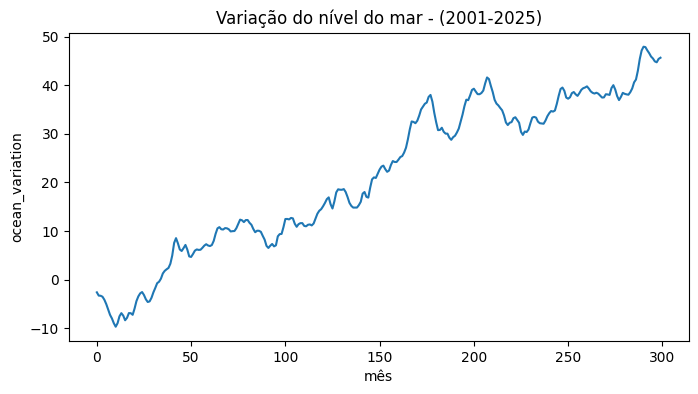

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(ts['ocean_variation'])
plt.title('Variação do nível do mar - (2001-2025)')
plt.xlabel('mês')
plt.ylabel('ocean_variation')
plt.show()

## Exercício

Faça a predição dos 5 últimos valores (`Test Data`) da série com base nos seguintes modelos:

1. Regressão Linear (ML), para 3 `lags`.
2. Regressão Linear (ML), para 10 `lags`.
3. Decision Tree Regressor (ML), para 3 `lags`.
4. Decision Tree Regressor (ML), para 10 `lags`.
5. ARIMA($p$,1,$q$), com $p$ e $q$ significativos.

Calcule para cada modelo o RMSE sobre os dados de treinamento e de teste construindo um dataframe como abaixo.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error
from sklearn.base import clone

def ml_timeseries_df(serie, n_lags):
    df_ml = pd.DataFrame()
    for i in range(n_lags, 0, -1):
        df_ml['t-' + str(i)] = serie.shift(i)
    df_ml['t'] = serie
    return df_ml.dropna().reset_index(drop=True)


serie = ts['ocean_variation']
test_size = 5
rmse = {}
residuos = {}
for reg in [LinearRegression(), DecisionTreeRegressor(random_state=seed)]:
    for n_lags in [3, 10]:
        dados = ml_timeseries_df(serie, n_lags)
        X_ts, y_ts = dados.drop(columns='t'), dados['t']
        X_train, X_test, y_train, y_test = X_ts[:-test_size], X_ts[-test_size:], y_ts[:-test_size], y_ts[-test_size:]
        model = clone(reg).fit(X_train, y_train)

        pred_train = model.predict(X_train)
        pred_test = model.predict(X_test)

        rmse[(str(reg), n_lags)] = [np.sqrt(mean_squared_error(y_train, pred_train)), np.sqrt(mean_squared_error(y_test, pred_test))]
        residuos[(str(reg), n_lags)] = (y_train - pred_train, y_test - pred_test)
        print(f'{str(reg)} ({n_lags} lags): RMSE train = {rmse[(str(reg), n_lags)][0]:.6f} | RMSE test = {rmse[(str(reg), n_lags)][1]:.6f}')

print()
display(pd.DataFrame(rmse, index=['Train Data', 'Test Data']).T)


LinearRegression() (3 lags): RMSE train = 0.589459 | RMSE test = 0.429531
LinearRegression() (10 lags): RMSE train = 0.562684 | RMSE test = 0.424190
DecisionTreeRegressor(random_state=42) (3 lags): RMSE train = 0.000000 | RMSE test = 1.938913
DecisionTreeRegressor(random_state=42) (10 lags): RMSE train = 0.000000 | RMSE test = 0.753777



Train Data  Test Data
LinearRegression()                     3     0.589459   0.429531
                                       10    0.562684   0.424190
DecisionTreeRegressor(random_state=42) 3     0.000000   1.938913
                                       10    0.000000   0.753777

In [ ]:
from statsmodels.tsa.arima.model import ARIMA

train, test = serie[:-test_size], serie[-test_size:]

p = 2
q = 1

model = ARIMA(train, order=(p, 1, q)).fit()

print(f'ARIMA({p},1,{q}) com coeficientes significativos')
print(model.summary())


ARIMA(2,1,1) com coeficientes significativos
                               SARIMAX Results                                
Dep. Variable:        ocean_variation   No. Observations:                  295
Model:                 ARIMA(2, 1, 1)   Log Likelihood                -254.474
Date:                Tue, 13 Oct 2026   AIC                            516.948
Time:                        15:24:17   BIC                            531.682
Sample:                             0   HQIC                           522.849
                                - 295                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.5358      0.102      5.262      0.000       0.336       0.735
ar.L2         -0.1981      0.087     -2.283      0.022      -0.368      -0.028
ma.L1  

In [ ]:
pred_train = model.fittedvalues[1:]
history = list(train)
pred_test = []

for t in test.index:
    pred_test.append(ARIMA(history, order=(p, 1, q)).fit().forecast()[0])
    history.append(test[t])

pred_teste = np.array(pred_test)
rmse[('ARIMA', p)] = [np.sqrt(mean_squared_error(train[1:], pred_train)), np.sqrt(mean_squared_error(test, pred_test))]

residuos[('ARIMA', p)] = (train[1:] - pred_train, test - pred_test)
print(f'ARIMA({p},1,{q}): RMSE train = {rmse[("ARIMA", p)][0]:.6f} | RMSE test = {rmse[("ARIMA", p)][1]:.6f}')

ARIMA(2,1,1): RMSE train = 0.574791 | RMSE test = 0.417984


### Salve seus dados

Salve seus dados como abaixo. Eles faram parte do seu arquivo `.pkl` como parte da sua resposta.

In [ ]:
RMSE_df = pd.DataFrame(rmse, index=['Train Data', 'Test Data']).T.rename_axis(['model', 'lags'])
RMSE_df

Train Data  Test Data
model                                  lags                       
LinearRegression()                     3       0.589459   0.429531
                                       10      0.562684   0.424190
DecisionTreeRegressor(random_state=42) 3       0.000000   1.938913
                                       10      0.000000   0.753777
ARIMA                                  2       0.574791   0.417984

10. Qual o melhor modelo segundo o menor erro no conjunto de treinamento e qual o RMSE obtido?
11. Qual o melhor modelo segundo o menor erro no conjunto de teste e qual o RMSE obtido?
12. Faça uma análise dos resíduos do melhor modelo de Aprendizado de Máquina comparando com os resíduos do modelo ARIMA.    


In [ ]:
residuos.keys()

dict_keys([('LinearRegression()', 3), ('LinearRegression()', 10), ('DecisionTreeRegressor(random_state=42)', 3), ('DecisionTreeRegressor(random_state=42)', 10), ('ARIMA', 2)])

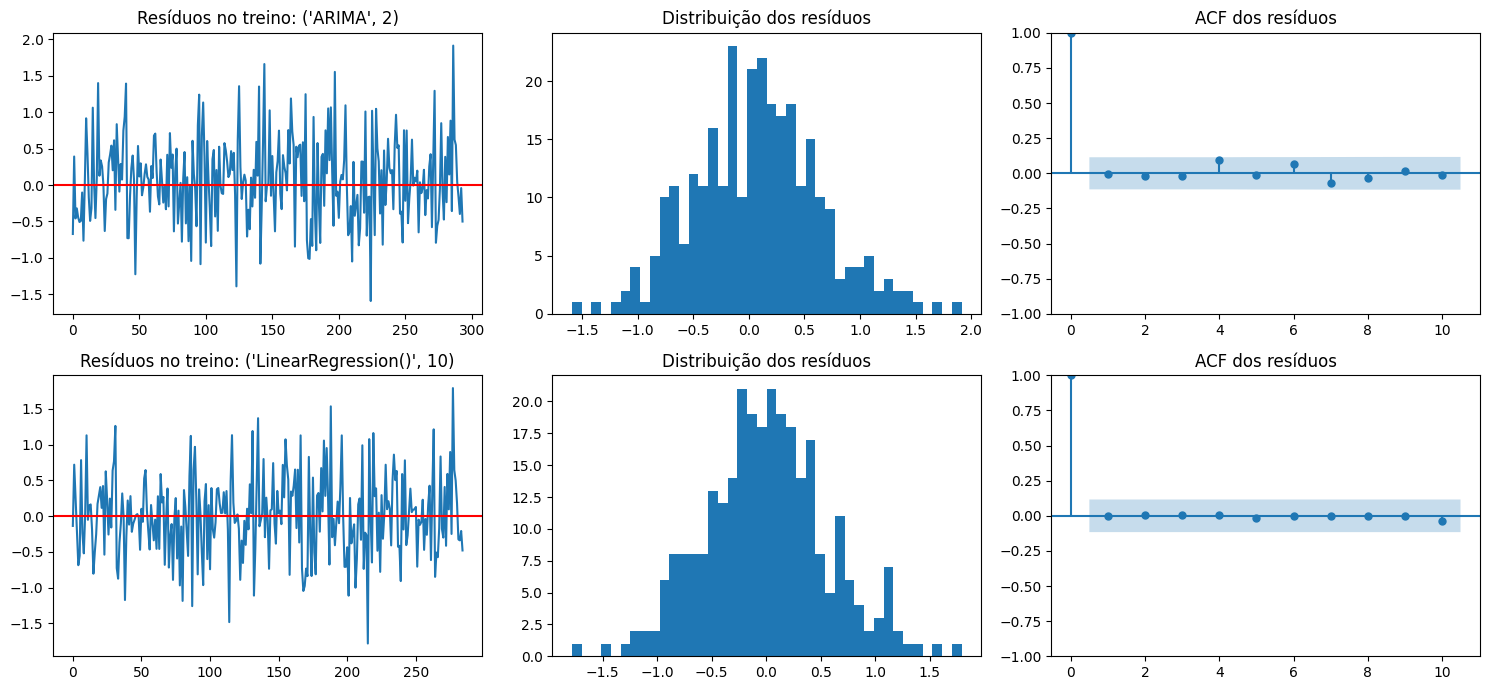

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import acf

fig, ax = plt.subplots(2, 3, figsize=(15, 7))

for i, key in enumerate([('ARIMA', 2), ('LinearRegression()', 10)]):
    res_train, _ = residuos[key]
    ax[i, 0].plot(res_train.values)
    ax[i, 0].axhline(0, color='red')
    ax[i, 0].set_title(f'Resíduos no treino: {key}')
    ax[i, 1].hist(res_train, bins=40)
    ax[i, 1].set_title('Distribuição dos resíduos')
    plot_acf(res_train, lags=10, ax=ax[i, 2], title='ACF dos resíduos')

plt.tight_layout()
plt.show()


# Respostas Finais `.pkl`





In [ ]:
#@markdown Execute para gerar e verificar suas respostas
import pickle

respostas = {}

if 'X_train_classificacao' in locals():
  respostas['X_train_classificacao'] = X_train_classificacao
else:
  respostas['X_train_classificacao'] = 'None'

if 'X_test_classificacao' in locals():
  respostas['X_test_classificacao'] = X_test_classificacao
else:
  respostas['X_test_classificacao'] = 'None'

if 'report_classificacao' in locals():
  respostas['report_classificacao'] = report_classificacao
else:
  respostas['report_classificacao'] = 'None'

if 'y_pred_classificacao' in locals():
  respostas['y_pred_classificacao'] = y_pred_classificacao
else:
  respostas['y_pred_classificacao'] = 'None'

if 'RMSE_df' in locals():
  respostas['RMSE_df'] = RMSE_df
else:
  respostas['RMSE_df'] = 'None'

# Define the filename with .pkl extension
filename = 'P3_' + Nome.replace(' ','_') + '_' + RA.replace('.','') + '.pkl'

# Serialize the dictionary to a pickle file
with open(filename, 'wb') as f:
      pickle.dump(respostas, f)

from IPython.display import display, HTML

# display(HTML('<span style="font-family: Georgia; font-size: 24px; color: blue;">Respostas</span>'))
display(HTML('<span style="font-size: 24px; color: blue;">Respostas</span>'))
print()
for key, value in respostas.items():
    print(f'{key}')

print()
display(HTML('<span style="font-size: 14px; color: blue;">Respostas salvas com sucesso em:</span>'))
print()
fname = f'<span style="font-size: 14px; color: blue;"><strong>{filename}</strong></span>'
display(HTML(fname))


X_train_classificacao
X_test_classificacao
report_classificacao
y_pred_classificacao
RMSE_df

